
# 07. Traditional ML vs. PepBERT — Model Evaluation

## Objective

Evaluate and compare traditional machine learning models and PepBERT for antimicrobial peptide activity prediction against *Escherichia coli* (EC) and *Staphylococcus aureus* (SA).

## Methods

- **Model selection:** Use the best feature, architecture, and hyperparameters selected by mean validation MSE across five random seeds (42–46).
- **Traditional ML:** Reconstruct the five seed-specific models using the selected feature and hyperparameters.
- **PepBERT:** Load the five pretrained and fine-tuned checkpoints for each selected architecture without additional training.
- **Validation and test:** Evaluate each seed-specific model using MSE, RMSE, MAE, R², Pearson correlation coefficient (PCC), and Kendall's tau (KTC).
- **Performance comparison:** Report the mean ± standard deviation (SD) across five seeds.
- **Representative model:** Select the checkpoint with the lowest validation MSE for model-specific visualizations.

## Outputs

- `results/ml_vs_pepbert/` — Validation and test results, summary tables, and figures.
- `models/traditional_ml/` — Traditional ML models.
- `models/pepbert/best_models/` — Representative PepBERT checkpoints.

The independent test datasets are used exclusively for final evaluation and not for model selection.


In [49]:

from pathlib import Path
import json
import shutil
import importlib

import numpy as np
import pandas as pd
import torch
import joblib

from configs.common import (
    ROOT, DATA_DIR, MODEL_DIR, RESULT_DIR, RANDOM_SEEDS
)

# Output directories
COMPARE_DIR = RESULT_DIR / "ml_vs_pepbert"
FIGURE_DIR = COMPARE_DIR / "figures"
ML_MODEL_DIR = MODEL_DIR / "traditional_ml" / "seed_models"
PEPBERT_BEST_DIR = MODEL_DIR / "pepbert" / "best_models"

for path in [COMPARE_DIR, FIGURE_DIR, ML_MODEL_DIR, PEPBERT_BEST_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Selected configurations
ml_best = pd.read_csv(
    RESULT_DIR / "traditional_ml" / "best_model_selection.csv"
)

pepbert_best = pd.read_csv(
    RESULT_DIR / "pepbert" / "best_hyperparameters.csv"
)

# Validation records
ml_validation = pd.read_csv(
    RESULT_DIR / "traditional_ml" / "validation_results.csv"
)

pepbert_grid = pd.read_csv(
    RESULT_DIR / "pepbert" / "grid_search_results.csv"
)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
print(f"Traditional ML: {len(ml_best)} configurations")
print(f"PepBERT: {len(pepbert_best)} configurations")
print(f"Seeds: {RANDOM_SEEDS}")


Device: cuda
Traditional ML: 8 configurations
PepBERT: 4 configurations
Seeds: [42, 43, 44, 45, 46]


In [50]:
# Load selected ML feature datasets
ml_datasets = {}

for _, row in ml_best.iterrows():
    target = row["Dataset"]
    feature = row["Feature"]
    key = (target, feature)

    if key not in ml_datasets:
        ml_datasets[key] = {
            "train": pd.read_csv(
                DATA_DIR / "features" / target / f"{feature}_Train.csv"
            ),
            "test": pd.read_csv(
                DATA_DIR / "features" / target / f"{feature}_Test.csv"
            ),
            "train_labels": pd.read_csv(
                DATA_DIR / f"{target}_Train.csv"
            ),
            "test_labels": pd.read_csv(
                DATA_DIR / f"{target}_Test.csv"
            ),
        }

# Dataset summary
for (target, feature), data in ml_datasets.items():
    print(
        f"{target} | {feature} | "
        f"Train: {data['train'].shape} | "
        f"Test: {data['test'].shape}"
    )

print("\nTarget columns:")
print(ml_datasets[("EC", "QSOrder")]["train_labels"].columns.tolist())


EC | QSOrder | Train: (7583, 48) | Test: (843, 48)
SA | QSOrder | Train: (6592, 48) | Test: (733, 48)

Target columns:
['sequence', 'species', 'original_strains', 'mic_uM', 'MIC_records', 'log10_MIC', 'length', 'pMIC']


In [51]:

import src.ml as ml
from tqdm import tqdm

from src.model_evaluation import evaluate_regression

# Traditional ML validation
ml_val_results = []
ml_val_predictions = []

total_runs = len(ml_best) * len(RANDOM_SEEDS)

with tqdm(total=total_runs, desc="ML Validation", unit="model") as pbar:

    for _, row in ml_best.iterrows():
        target = row["Dataset"]
        model_name = row["Model"]
        feature = row["Feature"]

        # Load original feature data
        X, y, _, _ = ml.load_ml_data(target, feature)

        # Selected hyperparameters
        params = json.loads(row["Best_Parameters"])

        for seed in RANDOM_SEEDS:

            # Original validation split
            train_idx, val_idx = ml.load_validation_split(
                target, seed
            )

            # Reconstruct the original model
            model = ml.create_model(
                model_name, params, seed
            )

            model.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            # Validation prediction
            y_true = y.iloc[val_idx].to_numpy()
            y_pred = model.predict(X.iloc[val_idx])

            metrics = evaluate_regression(y_true, y_pred)

            ml_val_results.append({
                "Dataset": target,
                "Model": model_name,
                "Feature": feature,
                "Seed": seed,
                **metrics
            })

            for idx, actual, predicted in zip(
                val_idx, y_true, y_pred
            ):
                ml_val_predictions.append({
                    "Dataset": target,
                    "Model": model_name,
                    "Feature": feature,
                    "Seed": seed,
                    "Sample_Index": int(idx),
                    "Actual": float(actual),
                    "Predicted": float(predicted)
                })

            # Save seed-specific model
            save_dir = ML_MODEL_DIR / target
            save_dir.mkdir(parents=True, exist_ok=True)

            joblib.dump(
                model,
                save_dir / f"{model_name}_{feature}_seed{seed}.joblib"
            )

            pbar.set_postfix(
                Dataset=target,
                Model=model_name,
                Seed=seed,
                Val_MSE=f"{metrics['MSE']:.4f}"
            )
            pbar.update(1)

# Save validation results
ml_val_results = pd.DataFrame(ml_val_results)
ml_val_predictions = pd.DataFrame(ml_val_predictions)

ml_val_results.to_csv(
    COMPARE_DIR / "ml_validation_results.csv",
    index=False
)

ml_val_predictions.to_csv(
    COMPARE_DIR / "ml_validation_predictions.csv",
    index=False
)

display(ml_val_results.round(4))


ML Validation: 100%|██████████| 40/40 [01:08<00:00,  1.72s/model, Dataset=SA, Model=SVR, Seed=46, Val_MSE=0.2544]


,Dataset,Model,Feature,Seed,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,42,0.4315,0.6569,0.5006,0.0977,0.4229,0.2728
1,EC,DT,QSOrder,43,0.3814,0.6175,0.4739,0.2643,0.5328,0.3373
2,EC,DT,QSOrder,44,0.3616,0.6013,0.4772,0.2687,0.5369,0.3107
3,EC,DT,QSOrder,45,0.3810,0.6172,0.4853,0.2027,0.5024,0.2792
4,EC,DT,QSOrder,46,0.4031,0.6349,0.4827,0.1783,0.4899,0.3140
5,EC,KNN,QSOrder,42,0.3127,0.5592,0.4142,0.3462,0.5981,0.4109
6,EC,KNN,QSOrder,43,0.3326,0.5767,0.4299,0.3584,0.6090,0.4208
7,EC,KNN,QSOrder,44,0.3089,0.5558,0.4208,0.3752,0.6263,0.4203
8,EC,KNN,QSOrder,45,0.2610,0.5109,0.3897,0.4538,0.6764,0.4421
9,EC,KNN,QSOrder,46,0.2725,0.5220,0.4000,0.4445,0.6757,0.4440


In [52]:

# Summarize ML validation metrics
METRICS = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

ml_val_summary = (
    ml_val_results
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .agg(
        **{
            f"{metric}_Mean": (metric, "mean")
            for metric in METRICS
        },
        **{
            f"{metric}_SD": (metric, "std")
            for metric in METRICS
        }
    )
)

# Format metrics as Mean ± SD
ml_val_table = ml_val_summary[
    ["Dataset", "Model", "Feature"]
].copy()

for metric in METRICS:
    ml_val_table[metric] = (
        ml_val_summary[f"{metric}_Mean"].map("{:.4f}".format)
        + " ± "
        + ml_val_summary[f"{metric}_SD"].map("{:.4f}".format)
    )

# Save results
ml_val_summary.to_csv(
    COMPARE_DIR / "ml_validation_summary.csv",
    index=False
)

ml_val_table.to_csv(
    COMPARE_DIR / "ml_validation_table.csv",
    index=False
)

display(ml_val_table)


,Dataset,Model,Feature,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,0.3917 ± 0.0267,0.6256 ± 0.0212,0.4839 ± 0.0104,0.2023 ± 0.0703,0.4970 ± 0.0460,0.3028 ± 0.0266
1,EC,KNN,QSOrder,0.2975 ± 0.0298,0.5449 ± 0.0275,0.4109 ± 0.0161,0.3956 ± 0.0500,0.6371 ± 0.0369,0.4276 ± 0.0146
2,EC,RF,QSOrder,0.2791 ± 0.0224,0.5280 ± 0.0211,0.4081 ± 0.0108,0.4329 ± 0.0338,0.6603 ± 0.0281,0.4443 ± 0.0203
3,EC,SVR,QSOrder,0.2808 ± 0.0270,0.5295 ± 0.0254,0.4011 ± 0.0186,0.4297 ± 0.0415,0.6560 ± 0.0315,0.4543 ± 0.0216
4,SA,DT,QSOrder,0.3724 ± 0.0156,0.6101 ± 0.0129,0.4784 ± 0.0088,0.1295 ± 0.0295,0.4147 ± 0.0173,0.2632 ± 0.0228
5,SA,KNN,QSOrder,0.2913 ± 0.0175,0.5395 ± 0.0164,0.4173 ± 0.0101,0.3189 ± 0.0407,0.5759 ± 0.0321,0.3769 ± 0.0226
6,SA,RF,QSOrder,0.2734 ± 0.0126,0.5228 ± 0.0122,0.4059 ± 0.0092,0.3608 ± 0.0257,0.6068 ± 0.0219,0.4181 ± 0.0274
7,SA,SVR,QSOrder,0.2794 ± 0.0163,0.5284 ± 0.0155,0.4027 ± 0.0074,0.3469 ± 0.0360,0.5913 ± 0.0306,0.4095 ± 0.0164


In [53]:
# PepBERT

In [54]:

from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split

import src.pepbert as pepbert_module
import src.pepbert_pretrained as pretrained_module
import configs.pepbert as pepbert_config

# Load pretrained PepBERT
model_module, pretrained_config, tokenizer, pretrained_weights = (
    pretrained_module.load_pretrained_pepbert()
)

# Prepare peptide datasets
pepbert_datasets = {}

for target in ["EC", "SA"]:
    df = pd.read_csv(DATA_DIR / f"{target}_Train.csv")

    pepbert_datasets[target] = pepbert_module.PeptideDataset(
        df,
        tokenizer,
        max_length=pepbert_config.MAX_LENGTH
    )

# Load selected seed-specific checkpoints
pepbert_grid = pd.read_csv(
    RESULT_DIR / "pepbert" / "grid_search_results.csv"
)

pepbert_selected = pepbert_grid.merge(
    pepbert_best[
        ["Dataset", "Pooling", "FC_Layers",
         "Learning_Rate", "Weight_Decay", "Dropout"]
    ],
    on=[
        "Dataset", "Pooling", "FC_Layers",
        "Learning_Rate", "Weight_Decay", "Dropout"
    ],
    how="inner"
).sort_values(
    ["Dataset", "Pooling", "Seed"]
).reset_index(drop=True)

print(f"PepBERT datasets: {list(pepbert_datasets)}")
print(f"Selected checkpoints: {len(pepbert_selected)}")
print(f"Device: {device}")


PepBERT datasets: ['EC', 'SA']
Selected checkpoints: 20
Device: cuda


In [55]:

from tqdm import tqdm

from src.model_evaluation import evaluate_regression

pepbert_val_results = []
pepbert_val_predictions = []

for _, row in tqdm(
    pepbert_selected.iterrows(),
    total=len(pepbert_selected),
    desc="PepBERT Validation",
    unit="model"
):
    target = row["Dataset"]
    pooling = row["Pooling"]
    fc_layers = int(row["FC_Layers"])
    seed = int(row["Seed"])

    # Validation split
    dataset = pepbert_datasets[target]

    _, val_idx = train_test_split(
        np.arange(len(dataset)),
        test_size=0.1,
        random_state=seed
    )

    val_loader = DataLoader(
        Subset(dataset, val_idx),
        batch_size=64,
        shuffle=False
    )

    # Build model
    encoder = pretrained_module.build_pretrained_encoder(
        model_module,
        pretrained_config,
        tokenizer,
        pretrained_weights
    )

    model = pepbert_module.PepBERTRegressor(
        encoder=encoder,
        hidden_size=320,
        pooling=pooling,
        fc_layers=fc_layers,
        dropout=float(row["Dropout"])
    ).to(device)

    # Load checkpoint
    filename = (
        f"FC{fc_layers}_"
        f"LR{row['Learning_Rate']:.0e}_"
        f"WD{row['Weight_Decay']:.0e}_"
        f"DO{row['Dropout']:.1f}_"
        f"seed{seed}.pt"
    )

    checkpoint_path = (
        MODEL_DIR / "pepbert" / target / pooling
        / "grid_search" / filename
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Validation prediction
    actuals = []
    predictions = []

    with torch.inference_mode():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            actuals.extend(batch["labels"].cpu().numpy().ravel())
            predictions.extend(outputs.cpu().numpy().ravel())

    metrics = evaluate_regression(actuals, predictions)
    feature = f"{pooling.upper()} (FC{fc_layers})"

    pepbert_val_results.append({
        "Dataset": target,
        "Model": "PepBERT",
        "Feature": feature,
        "Seed": seed,
        **metrics
    })

    for idx, actual, predicted in zip(
        val_idx, actuals, predictions
    ):
        pepbert_val_predictions.append({
            "Dataset": target,
            "Model": "PepBERT",
            "Feature": feature,
            "Seed": seed,
            "Sample_Index": int(idx),
            "Actual": float(actual),
            "Predicted": float(predicted)
        })

# Save validation results
pepbert_val_results = pd.DataFrame(pepbert_val_results)
pepbert_val_predictions = pd.DataFrame(pepbert_val_predictions)

pepbert_val_results.to_csv(
    COMPARE_DIR / "pepbert_validation_results.csv",
    index=False
)

pepbert_val_predictions.to_csv(
    COMPARE_DIR / "pepbert_validation_predictions.csv",
    index=False
)

display(pepbert_val_results.round(4))


PepBERT Validation: 100%|██████████| 20/20 [00:03<00:00,  5.31model/s]


,Dataset,Model,Feature,Seed,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,PepBERT,MEAN (FC3),42,0.2774,0.5267,0.3878,0.4200,0.6682,0.4777
1,EC,PepBERT,MEAN (FC3),43,0.2860,0.5348,0.3946,0.4483,0.6886,0.4950
2,EC,PepBERT,MEAN (FC3),44,0.2729,0.5224,0.3994,0.4481,0.6727,0.4582
3,EC,PepBERT,MEAN (FC3),45,0.2328,0.4825,0.3699,0.5128,0.7200,0.4786
4,EC,PepBERT,MEAN (FC3),46,0.2410,0.4909,0.3755,0.5087,0.7153,0.4954
5,EC,PepBERT,SOS (FC1),42,0.2707,0.5203,0.3856,0.4340,0.6682,0.4723
6,EC,PepBERT,SOS (FC1),43,0.2737,0.5232,0.3867,0.4719,0.6912,0.4958
7,EC,PepBERT,SOS (FC1),44,0.2589,0.5089,0.3822,0.4763,0.6958,0.4846
8,EC,PepBERT,SOS (FC1),45,0.2322,0.4819,0.3711,0.5140,0.7220,0.4840
9,EC,PepBERT,SOS (FC1),46,0.2235,0.4728,0.3595,0.5443,0.7386,0.5177


In [56]:

# Combine validation results
validation_results = pd.concat(
    [ml_val_results, pepbert_val_results],
    ignore_index=True
)

# Summarize metrics across five seeds
METRICS = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

validation_summary = (
    validation_results
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .agg(
        **{
            f"{metric}_Mean": (metric, "mean")
            for metric in METRICS
        },
        **{
            f"{metric}_SD": (metric, "std")
            for metric in METRICS
        }
    )
)

# Create publication-style table
validation_table = validation_summary[
    ["Dataset", "Model", "Feature"]
].copy()

for metric in METRICS:
    validation_table[metric] = (
        validation_summary[f"{metric}_Mean"].map("{:.4f}".format)
        + " ± "
        + validation_summary[f"{metric}_SD"].map("{:.4f}".format)
    )

# Save results
validation_results.to_csv(
    COMPARE_DIR / "validation_results.csv",
    index=False
)

validation_summary.to_csv(
    COMPARE_DIR / "validation_summary.csv",
    index=False
)

validation_table.to_csv(
    COMPARE_DIR / "validation_table.csv",
    index=False
)

display(validation_table)


,Dataset,Model,Feature,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,0.3917 ± 0.0267,0.6256 ± 0.0212,0.4839 ± 0.0104,0.2023 ± 0.0703,0.4970 ± 0.0460,0.3028 ± 0.0266
1,EC,KNN,QSOrder,0.2975 ± 0.0298,0.5449 ± 0.0275,0.4109 ± 0.0161,0.3956 ± 0.0500,0.6371 ± 0.0369,0.4276 ± 0.0146
2,EC,PepBERT,MEAN (FC3),0.2620 ± 0.0236,0.5114 ± 0.0232,0.3854 ± 0.0125,0.4676 ± 0.0411,0.6930 ± 0.0238,0.4810 ± 0.0153
3,EC,PepBERT,SOS (FC1),0.2518 ± 0.0228,0.5014 ± 0.0228,0.3770 ± 0.0116,0.4881 ± 0.0423,0.7032 ± 0.0275,0.4909 ± 0.0171
4,EC,RF,QSOrder,0.2791 ± 0.0224,0.5280 ± 0.0211,0.4081 ± 0.0108,0.4329 ± 0.0338,0.6603 ± 0.0281,0.4443 ± 0.0203
5,EC,SVR,QSOrder,0.2808 ± 0.0270,0.5295 ± 0.0254,0.4011 ± 0.0186,0.4297 ± 0.0415,0.6560 ± 0.0315,0.4543 ± 0.0216
6,SA,DT,QSOrder,0.3724 ± 0.0156,0.6101 ± 0.0129,0.4784 ± 0.0088,0.1295 ± 0.0295,0.4147 ± 0.0173,0.2632 ± 0.0228
7,SA,KNN,QSOrder,0.2913 ± 0.0175,0.5395 ± 0.0164,0.4173 ± 0.0101,0.3189 ± 0.0407,0.5759 ± 0.0321,0.3769 ± 0.0226
8,SA,PepBERT,MEAN (FC1),0.2716 ± 0.0190,0.5209 ± 0.0181,0.3957 ± 0.0142,0.3645 ± 0.0520,0.6258 ± 0.0295,0.4309 ± 0.0217
9,SA,PepBERT,SOS (FC2),0.2558 ± 0.0107,0.5057 ± 0.0106,0.3897 ± 0.0117,0.4014 ± 0.0384,0.6435 ± 0.0276,0.4358 ± 0.0216


In [57]:

# Select representative models by validation MSE
best_models = (
    validation_results
    .sort_values(["Dataset", "Model", "Feature", "MSE", "Seed"])
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .first()
)

# Keep model selection information
best_models = best_models[
    ["Dataset", "Model", "Feature", "Seed", "MSE"]
].rename(columns={"MSE": "Validation_MSE"})

best_models["Model_Path"] = ""

# Save representative models
for idx, row in best_models.iterrows():
    target = row["Dataset"]
    model_name = row["Model"]
    feature = row["Feature"]
    seed = int(row["Seed"])

    if model_name == "PepBERT":
        selected = pepbert_selected[
            (pepbert_selected["Dataset"] == target)
            & (pepbert_selected["Seed"] == seed)
            & (
                pepbert_selected["Pooling"].str.upper()
                == feature.split(" ")[0]
            )
        ].iloc[0]

        pooling = selected["Pooling"]
        fc = int(selected["FC_Layers"])

        filename = (
            f"FC{fc}_"
            f"LR{selected['Learning_Rate']:.0e}_"
            f"WD{selected['Weight_Decay']:.0e}_"
            f"DO{selected['Dropout']:.1f}_"
            f"seed{seed}.pt"
        )

        source = (
            MODEL_DIR / "pepbert" / target / pooling
            / "grid_search" / filename
        )

        destination = (
            PEPBERT_BEST_DIR / f"{target}_{pooling}_best.pt"
        )

    else:
        source = (
            ML_MODEL_DIR / target
            / f"{model_name}_{feature}_seed{seed}.joblib"
        )

        destination = (
            MODEL_DIR / "traditional_ml" / target
            / f"{model_name}_{feature}_best.joblib"
        )

        destination.parent.mkdir(parents=True, exist_ok=True)

    shutil.copy2(source, destination)
    best_models.loc[idx, "Model_Path"] = str(destination)

# Save selection table
best_models.to_csv(
    COMPARE_DIR / "best_models.csv",
    index=False
)

display(best_models)


,Dataset,Model,Feature,Seed,Validation_MSE,Model_Path
0,EC,DT,QSOrder,44,0.361581,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
1,EC,KNN,QSOrder,45,0.260995,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
2,EC,PepBERT,MEAN (FC3),45,0.232777,C:\Users\jinwo\Desktop\PepBert_REV\models\pepb...
3,EC,PepBERT,SOS (FC1),46,0.223535,C:\Users\jinwo\Desktop\PepBert_REV\models\pepb...
4,EC,RF,QSOrder,45,0.256164,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
5,EC,SVR,QSOrder,45,0.252182,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
6,SA,DT,QSOrder,45,0.346912,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
7,SA,KNN,QSOrder,46,0.262895,C:\Users\jinwo\Desktop\PepBert_REV\models\trad...
8,SA,PepBERT,MEAN (FC1),42,0.250925,C:\Users\jinwo\Desktop\PepBert_REV\models\pepb...
9,SA,PepBERT,SOS (FC2),46,0.241720,C:\Users\jinwo\Desktop\PepBert_REV\models\pepb...


In [58]:
#TEST

In [59]:

from tqdm.auto import tqdm

# Traditional ML test evaluation
ml_test_results = []
ml_test_predictions = []

total_runs = len(ml_best) * len(RANDOM_SEEDS)

with tqdm(total=total_runs, desc="ML Test", unit="model") as pbar:

    for _, row in ml_best.iterrows():
        target = row["Dataset"]
        model_name = row["Model"]
        feature = row["Feature"]

        data = ml_datasets[(target, feature)]

        # Test features and labels
        X_test = data["test"].select_dtypes(include="number")
        X_test = X_test.drop(
            columns=["pMIC", "MIC", "Unnamed: 0"],
            errors="ignore"
        )
        y_test = data["test_labels"]["pMIC"].to_numpy()

        for seed in RANDOM_SEEDS:

            # Load trained model
            model_path = (
                ML_MODEL_DIR / target
                / f"{model_name}_{feature}_seed{seed}.joblib"
            )
            model = joblib.load(model_path)

            # Test prediction
            y_pred = model.predict(X_test)

            metrics = evaluate_regression(y_test, y_pred)

            ml_test_results.append({
                "Dataset": target,
                "Model": model_name,
                "Feature": feature,
                "Seed": seed,
                **metrics
            })

            for idx, (actual, predicted) in enumerate(zip(y_test, y_pred)):
                ml_test_predictions.append({
                    "Dataset": target,
                    "Model": model_name,
                    "Feature": feature,
                    "Seed": seed,
                    "Sample_Index": idx,
                    "Actual": float(actual),
                    "Predicted": float(predicted)
                })

            pbar.set_postfix(
                Dataset=target,
                Model=model_name,
                Seed=seed,
                Test_MSE=f"{metrics['MSE']:.4f}"
            )
            pbar.update(1)

# Save test results
ml_test_results = pd.DataFrame(ml_test_results)
ml_test_predictions = pd.DataFrame(ml_test_predictions)

ml_test_results.to_csv(
    COMPARE_DIR / "ml_test_results.csv",
    index=False
)

ml_test_predictions.to_csv(
    COMPARE_DIR / "ml_test_predictions.csv",
    index=False
)

display(ml_test_results.round(4))


ML Test:   0%|          | 0/40 [00:00<?, ?model/s]

,Dataset,Model,Feature,Seed,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,42,0.4137,0.6432,0.4937,0.1517,0.4547,0.2849
1,EC,DT,QSOrder,43,0.3993,0.6319,0.4858,0.1812,0.4681,0.2853
2,EC,DT,QSOrder,44,0.3973,0.6303,0.4838,0.1853,0.4661,0.2971
3,EC,DT,QSOrder,45,0.3970,0.6301,0.4879,0.1860,0.4766,0.2892
4,EC,DT,QSOrder,46,0.3926,0.6266,0.4869,0.1950,0.4886,0.2889
5,EC,KNN,QSOrder,42,0.3070,0.5541,0.4239,0.3705,0.6163,0.4093
6,EC,KNN,QSOrder,43,0.3184,0.5643,0.4287,0.3472,0.5993,0.4025
7,EC,KNN,QSOrder,44,0.3061,0.5532,0.4241,0.3725,0.6169,0.4099
8,EC,KNN,QSOrder,45,0.3073,0.5543,0.4260,0.3700,0.6158,0.4111
9,EC,KNN,QSOrder,46,0.3144,0.5607,0.4308,0.3553,0.6060,0.4015


In [60]:

# Summarize ML test metrics
METRICS = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

ml_test_summary = (
    ml_test_results
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .agg(
        **{
            f"{metric}_Mean": (metric, "mean")
            for metric in METRICS
        },
        **{
            f"{metric}_SD": (metric, "std")
            for metric in METRICS
        }
    )
)

# Format as Mean ± SD
ml_test_table = ml_test_summary[
    ["Dataset", "Model", "Feature"]
].copy()

for metric in METRICS:
    ml_test_table[metric] = (
        ml_test_summary[f"{metric}_Mean"].map("{:.4f}".format)
        + " ± "
        + ml_test_summary[f"{metric}_SD"].map("{:.4f}".format)
    )

# Save test summaries
ml_test_summary.to_csv(
    COMPARE_DIR / "ml_test_summary.csv",
    index=False
)

ml_test_table.to_csv(
    COMPARE_DIR / "ml_test_table.csv",
    index=False
)

display(ml_test_table)


,Dataset,Model,Feature,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,0.4000 ± 0.0081,0.6324 ± 0.0063,0.4876 ± 0.0037,0.1798 ± 0.0165,0.4708 ± 0.0126,0.2891 ± 0.0049
1,EC,KNN,QSOrder,0.3106 ± 0.0055,0.5573 ± 0.0049,0.4267 ± 0.0030,0.3631 ± 0.0112,0.6108 ± 0.0079,0.4068 ± 0.0045
2,EC,RF,QSOrder,0.2934 ± 0.0021,0.5417 ± 0.0020,0.4127 ± 0.0024,0.3984 ± 0.0044,0.6335 ± 0.0037,0.4331 ± 0.0032
3,EC,SVR,QSOrder,0.3087 ± 0.0041,0.5556 ± 0.0037,0.4177 ± 0.0022,0.3671 ± 0.0084,0.6064 ± 0.0067,0.4274 ± 0.0044
4,SA,DT,QSOrder,0.3895 ± 0.0229,0.6239 ± 0.0182,0.4875 ± 0.0103,0.0641 ± 0.0550,0.3766 ± 0.0363,0.2209 ± 0.0192
5,SA,KNN,QSOrder,0.2989 ± 0.0054,0.5467 ± 0.0049,0.4138 ± 0.0020,0.2818 ± 0.0130,0.5460 ± 0.0096,0.3538 ± 0.0067
6,SA,RF,QSOrder,0.2700 ± 0.0049,0.5196 ± 0.0048,0.4058 ± 0.0030,0.3512 ± 0.0119,0.5940 ± 0.0106,0.3986 ± 0.0067
7,SA,SVR,QSOrder,0.2920 ± 0.0032,0.5404 ± 0.0029,0.4056 ± 0.0021,0.2985 ± 0.0076,0.5484 ± 0.0068,0.3810 ± 0.0065


In [61]:

# Prepare independent test datasets
pepbert_test_datasets = {}

for target in ["EC", "SA"]:
    df = pd.read_csv(DATA_DIR / f"{target}_Test.csv")

    pepbert_test_datasets[target] = pepbert_module.PeptideDataset(
        df,
        tokenizer,
        max_length=pepbert_config.MAX_LENGTH
    )

# Evaluate saved checkpoints
pepbert_test_results = []
pepbert_test_predictions = []

for _, row in tqdm(
    pepbert_selected.iterrows(),
    total=len(pepbert_selected),
    desc="PepBERT Test",
    unit="model"
):
    target = row["Dataset"]
    pooling = row["Pooling"]
    fc_layers = int(row["FC_Layers"])
    seed = int(row["Seed"])

    test_loader = DataLoader(
        pepbert_test_datasets[target],
        batch_size=64,
        shuffle=False
    )

    # Build model
    encoder = pretrained_module.build_pretrained_encoder(
        model_module,
        pretrained_config,
        tokenizer,
        pretrained_weights
    )

    model = pepbert_module.PepBERTRegressor(
        encoder=encoder,
        hidden_size=320,
        pooling=pooling,
        fc_layers=fc_layers,
        dropout=float(row["Dropout"])
    ).to(device)

    # Load selected checkpoint
    filename = (
        f"FC{fc_layers}_"
        f"LR{row['Learning_Rate']:.0e}_"
        f"WD{row['Weight_Decay']:.0e}_"
        f"DO{row['Dropout']:.1f}_"
        f"seed{seed}.pt"
    )

    checkpoint_path = (
        MODEL_DIR / "pepbert" / target / pooling
        / "grid_search" / filename
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # Test prediction
    actuals = []
    predictions = []

    with torch.inference_mode():
        for batch in test_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            actuals.extend(
                batch["labels"].cpu().numpy().ravel()
            )
            predictions.extend(
                outputs.cpu().numpy().ravel()
            )

    metrics = evaluate_regression(actuals, predictions)
    feature = f"{pooling.upper()} (FC{fc_layers})"

    pepbert_test_results.append({
        "Dataset": target,
        "Model": "PepBERT",
        "Feature": feature,
        "Seed": seed,
        **metrics
    })

    for idx, (actual, predicted) in enumerate(
        zip(actuals, predictions)
    ):
        pepbert_test_predictions.append({
            "Dataset": target,
            "Model": "PepBERT",
            "Feature": feature,
            "Seed": seed,
            "Sample_Index": idx,
            "Actual": float(actual),
            "Predicted": float(predicted)
        })

    del model, encoder

# Save test results
pepbert_test_results = pd.DataFrame(pepbert_test_results)
pepbert_test_predictions = pd.DataFrame(pepbert_test_predictions)

pepbert_test_results.to_csv(
    COMPARE_DIR / "pepbert_test_results.csv",
    index=False
)

pepbert_test_predictions.to_csv(
    COMPARE_DIR / "pepbert_test_predictions.csv",
    index=False
)

display(pepbert_test_results.round(4))


PepBERT Test:   0%|          | 0/20 [00:00<?, ?model/s]

,Dataset,Model,Feature,Seed,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,PepBERT,MEAN (FC3),42,0.2629,0.5128,0.3879,0.4609,0.6952,0.4869
1,EC,PepBERT,MEAN (FC3),43,0.2845,0.5334,0.3977,0.4167,0.6644,0.4753
2,EC,PepBERT,MEAN (FC3),44,0.2579,0.5079,0.3885,0.4711,0.6889,0.4816
3,EC,PepBERT,MEAN (FC3),45,0.2568,0.5068,0.3850,0.4735,0.6936,0.4806
4,EC,PepBERT,MEAN (FC3),46,0.2787,0.5279,0.4025,0.4286,0.6624,0.4577
5,EC,PepBERT,SOS (FC1),42,0.2667,0.5165,0.3906,0.4531,0.6813,0.4765
6,EC,PepBERT,SOS (FC1),43,0.2554,0.5054,0.3731,0.4764,0.6928,0.4994
7,EC,PepBERT,SOS (FC1),44,0.2457,0.4957,0.3666,0.4962,0.7049,0.5120
8,EC,PepBERT,SOS (FC1),45,0.2625,0.5124,0.3912,0.4617,0.6876,0.4785
9,EC,PepBERT,SOS (FC1),46,0.2652,0.5150,0.3915,0.4562,0.6775,0.4796


In [62]:

# Summarize PepBERT test metrics
METRICS = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

pepbert_test_summary = (
    pepbert_test_results
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .agg(
        **{
            f"{metric}_Mean": (metric, "mean")
            for metric in METRICS
        },
        **{
            f"{metric}_SD": (metric, "std")
            for metric in METRICS
        }
    )
)

# Format as Mean ± SD
pepbert_test_table = pepbert_test_summary[
    ["Dataset", "Model", "Feature"]
].copy()

for metric in METRICS:
    pepbert_test_table[metric] = (
        pepbert_test_summary[f"{metric}_Mean"].map("{:.4f}".format)
        + " ± "
        + pepbert_test_summary[f"{metric}_SD"].map("{:.4f}".format)
    )

# Save test summaries
pepbert_test_summary.to_csv(
    COMPARE_DIR / "pepbert_test_summary.csv",
    index=False
)

pepbert_test_table.to_csv(
    COMPARE_DIR / "pepbert_test_table.csv",
    index=False
)

display(pepbert_test_table)


,Dataset,Model,Feature,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,PepBERT,MEAN (FC3),0.2682 ± 0.0126,0.5177 ± 0.0121,0.3923 ± 0.0074,0.4501 ± 0.0259,0.6809 ± 0.0161,0.4764 ± 0.0112
1,EC,PepBERT,SOS (FC1),0.2591 ± 0.0087,0.5090 ± 0.0086,0.3826 ± 0.0119,0.4687 ± 0.0178,0.6888 ± 0.0107,0.4892 ± 0.0158
2,SA,PepBERT,MEAN (FC1),0.2646 ± 0.0170,0.5142 ± 0.0164,0.3879 ± 0.0141,0.3642 ± 0.0407,0.6243 ± 0.0251,0.4269 ± 0.0213
3,SA,PepBERT,SOS (FC2),0.2709 ± 0.0168,0.5203 ± 0.0161,0.3994 ± 0.0140,0.3492 ± 0.0404,0.6087 ± 0.0260,0.4044 ± 0.0245


In [63]:

# Combine test results
test_results = pd.concat(
    [ml_test_results, pepbert_test_results],
    ignore_index=True
)

# Summarize six metrics across five seeds
METRICS = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

test_summary = (
    test_results
    .groupby(["Dataset", "Model", "Feature"], as_index=False)
    .agg(
        **{
            f"{metric}_Mean": (metric, "mean")
            for metric in METRICS
        },
        **{
            f"{metric}_SD": (metric, "std")
            for metric in METRICS
        }
    )
)

# Create publication-style table
test_table = test_summary[
    ["Dataset", "Model", "Feature"]
].copy()

for metric in METRICS:
    test_table[metric] = (
        test_summary[f"{metric}_Mean"].map("{:.4f}".format)
        + " ± "
        + test_summary[f"{metric}_SD"].map("{:.4f}".format)
    )

# Save combined test results
test_results.to_csv(
    COMPARE_DIR / "test_results.csv",
    index=False
)

test_summary.to_csv(
    COMPARE_DIR / "test_summary.csv",
    index=False
)

test_table.to_csv(
    COMPARE_DIR / "test_table.csv",
    index=False
)

display(test_table)


,Dataset,Model,Feature,MSE,RMSE,MAE,R2,PCC,KTC
0,EC,DT,QSOrder,0.4000 ± 0.0081,0.6324 ± 0.0063,0.4876 ± 0.0037,0.1798 ± 0.0165,0.4708 ± 0.0126,0.2891 ± 0.0049
1,EC,KNN,QSOrder,0.3106 ± 0.0055,0.5573 ± 0.0049,0.4267 ± 0.0030,0.3631 ± 0.0112,0.6108 ± 0.0079,0.4068 ± 0.0045
2,EC,PepBERT,MEAN (FC3),0.2682 ± 0.0126,0.5177 ± 0.0121,0.3923 ± 0.0074,0.4501 ± 0.0259,0.6809 ± 0.0161,0.4764 ± 0.0112
3,EC,PepBERT,SOS (FC1),0.2591 ± 0.0087,0.5090 ± 0.0086,0.3826 ± 0.0119,0.4687 ± 0.0178,0.6888 ± 0.0107,0.4892 ± 0.0158
4,EC,RF,QSOrder,0.2934 ± 0.0021,0.5417 ± 0.0020,0.4127 ± 0.0024,0.3984 ± 0.0044,0.6335 ± 0.0037,0.4331 ± 0.0032
5,EC,SVR,QSOrder,0.3087 ± 0.0041,0.5556 ± 0.0037,0.4177 ± 0.0022,0.3671 ± 0.0084,0.6064 ± 0.0067,0.4274 ± 0.0044
6,SA,DT,QSOrder,0.3895 ± 0.0229,0.6239 ± 0.0182,0.4875 ± 0.0103,0.0641 ± 0.0550,0.3766 ± 0.0363,0.2209 ± 0.0192
7,SA,KNN,QSOrder,0.2989 ± 0.0054,0.5467 ± 0.0049,0.4138 ± 0.0020,0.2818 ± 0.0130,0.5460 ± 0.0096,0.3538 ± 0.0067
8,SA,PepBERT,MEAN (FC1),0.2646 ± 0.0170,0.5142 ± 0.0164,0.3879 ± 0.0141,0.3642 ± 0.0407,0.6243 ± 0.0251,0.4269 ± 0.0213
9,SA,PepBERT,SOS (FC2),0.2709 ± 0.0168,0.5203 ± 0.0161,0.3994 ± 0.0140,0.3492 ± 0.0404,0.6087 ± 0.0260,0.4044 ± 0.0245


In [64]:
# Figure

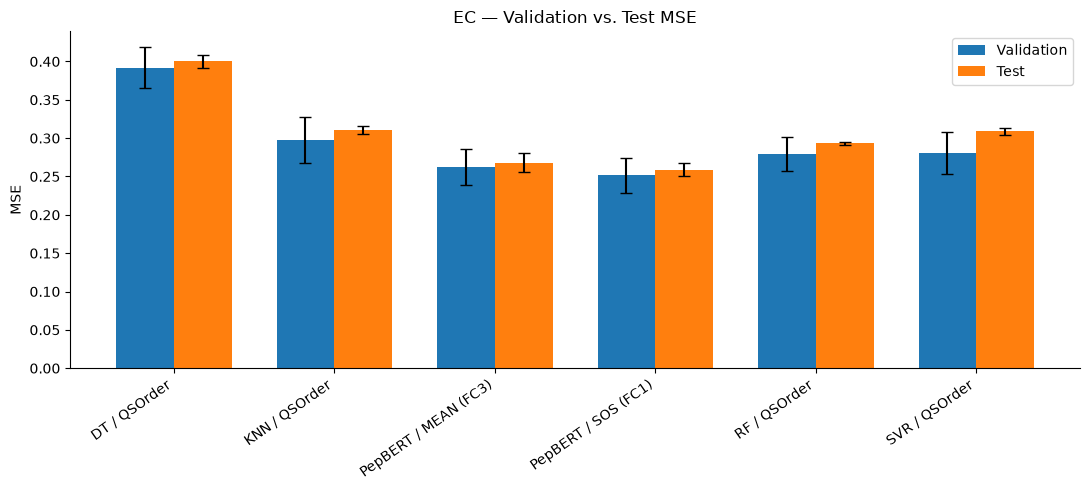

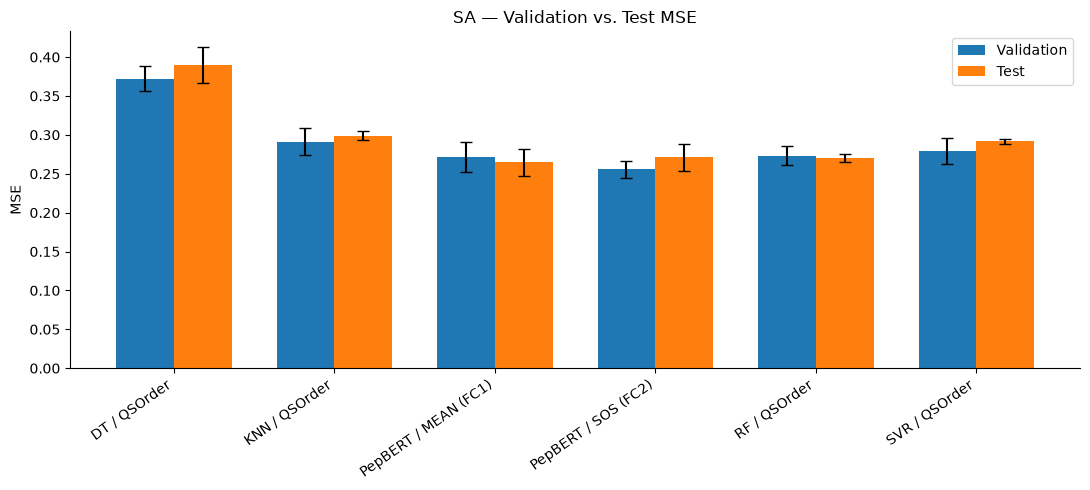

In [65]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from configs.common import RESULT_DIR

# Load saved results
FIGURE_DATA_DIR = RESULT_DIR / "ml_vs_pepbert"
FIGURE_DIR = FIGURE_DATA_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

validation_df = pd.read_csv(
    FIGURE_DATA_DIR / "validation_summary.csv"
)

test_df = pd.read_csv(
    FIGURE_DATA_DIR / "test_summary.csv"
)

# Prepare MSE data
frames = []

for split, df in [
    ("Validation", validation_df),
    ("Test", test_df)
]:
    temp = df[
        ["Dataset", "Model", "Feature", "MSE_Mean", "MSE_SD"]
    ].copy()

    temp["Split"] = split
    temp["Label"] = temp["Model"] + " / " + temp["Feature"]
    frames.append(temp)

mse_comparison = pd.concat(frames, ignore_index=True)

# Draw figures
for target in ["EC", "SA"]:
    df = mse_comparison[mse_comparison["Dataset"] == target]
    labels = df["Label"].drop_duplicates().tolist()

    x = np.arange(len(labels))
    width = 0.36

    fig, ax = plt.subplots(figsize=(11, 5))

    for i, split in enumerate(["Validation", "Test"]):
        values = (
            df[df["Split"] == split]
            .set_index("Label")
            .loc[labels]
        )

        ax.bar(
            x + (i - 0.5) * width,
            values["MSE_Mean"],
            width,
            yerr=values["MSE_SD"],
            capsize=4,
            label=split
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_ylabel("MSE")
    ax.set_title(f"{target} — Validation vs. Test MSE")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / f"{target}_validation_test_mse.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


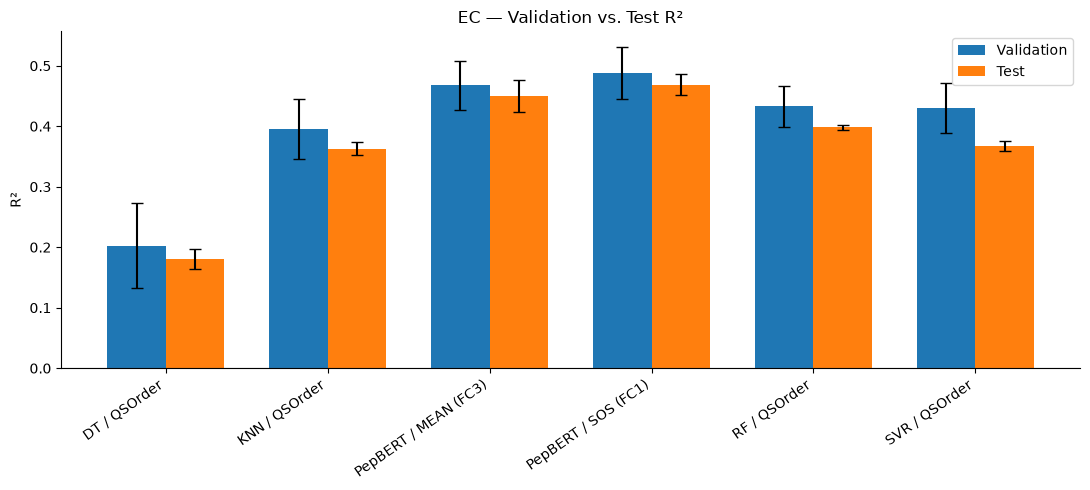

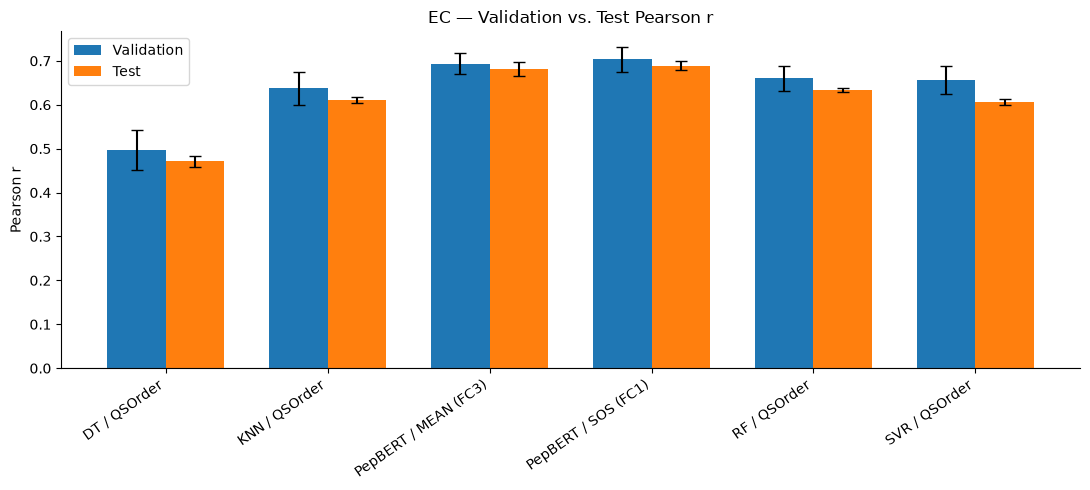

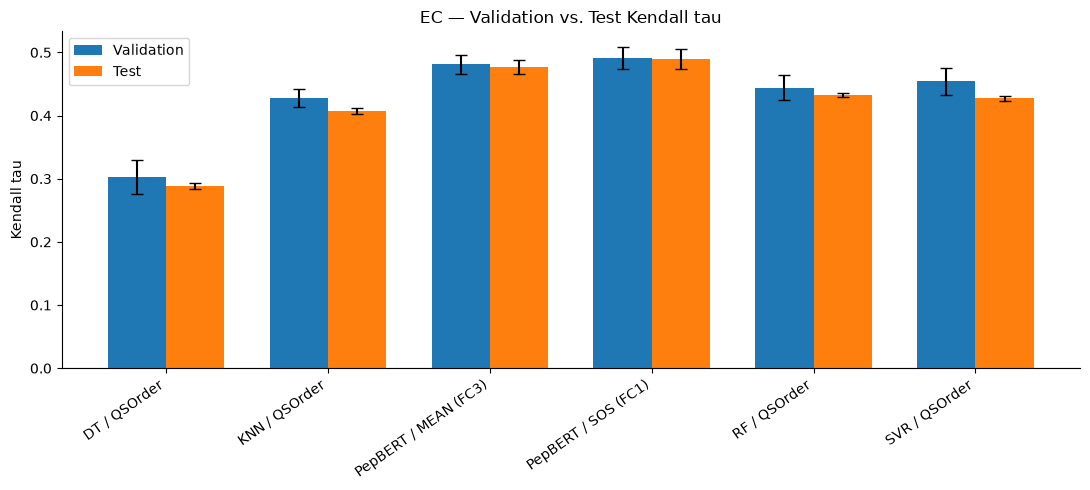

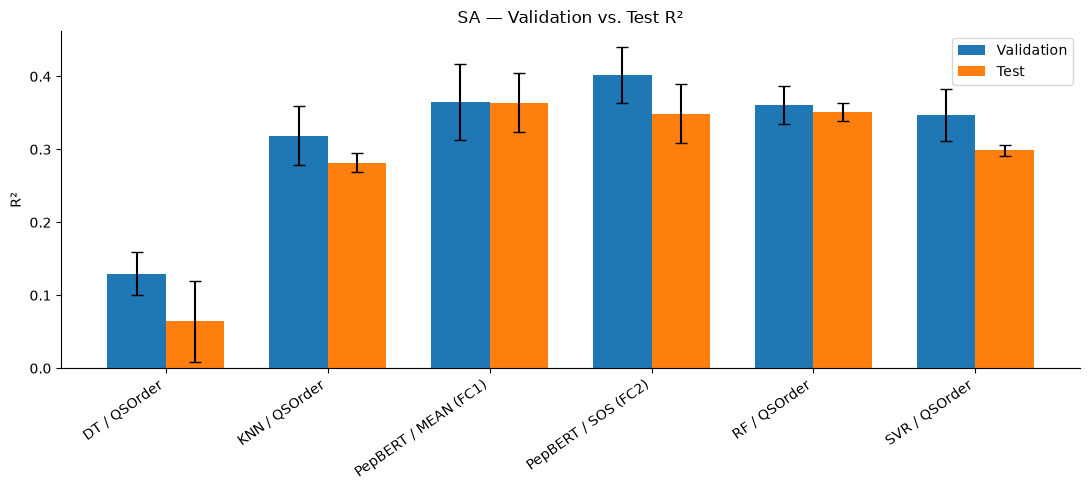

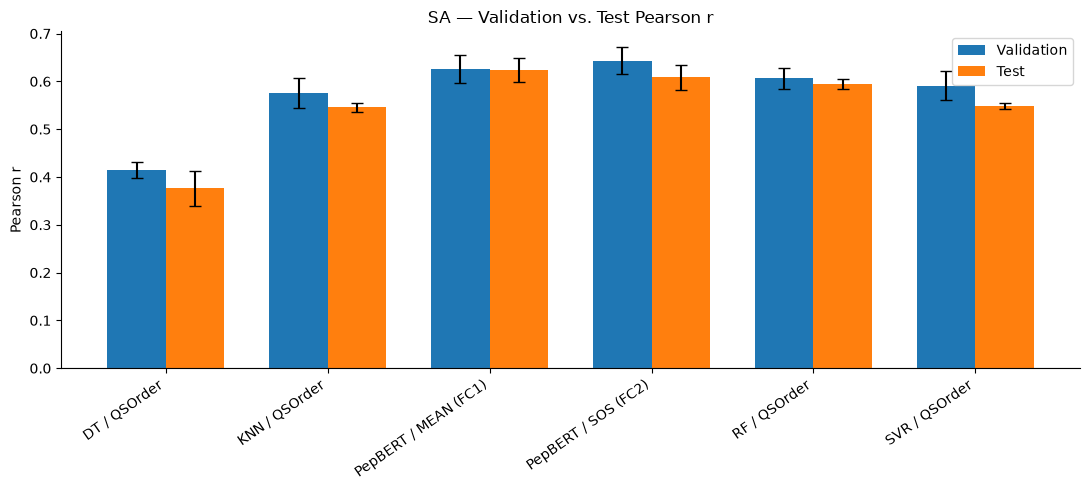

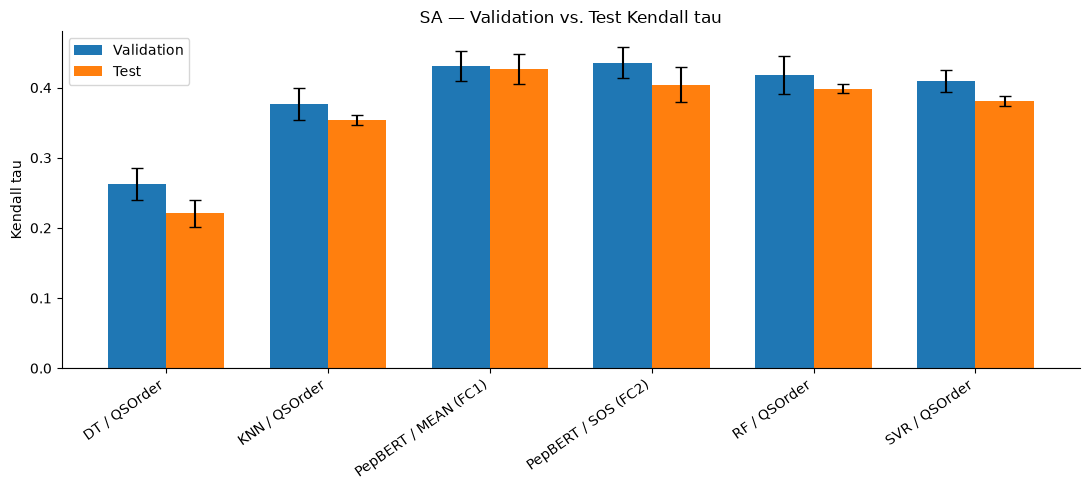

In [66]:

# Plot additional performance metrics
metrics = {
    "R2": "R²",
    "PCC": "Pearson r",
    "KTC": "Kendall tau"
}

for target in ["EC", "SA"]:
    val = validation_df[
        validation_df["Dataset"] == target
    ].set_index(["Model", "Feature"])

    test = test_df[
        test_df["Dataset"] == target
    ].set_index(["Model", "Feature"])

    # Match model order
    test = test.reindex(val.index)

    labels = [
        f"{model} / {feature}"
        for model, feature in val.index
    ]

    x = np.arange(len(labels))
    width = 0.36

    for metric, ylabel in metrics.items():
        fig, ax = plt.subplots(figsize=(11, 5))

        for i, (split, data) in enumerate([
            ("Validation", val),
            ("Test", test)
        ]):
            ax.bar(
                x + (i - 0.5) * width,
                data[f"{metric}_Mean"].to_numpy(),
                width,
                yerr=data[f"{metric}_SD"].to_numpy(),
                capsize=4,
                label=split
            )

        ax.axhline(0, linewidth=0.8, color="gray")
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=35, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{target} — Validation vs. Test {ylabel}")
        ax.legend()
        ax.spines[["top", "right"]].set_visible(False)

        fig.tight_layout()
        fig.savefig(
            FIGURE_DIR / f"{target}_validation_test_{metric.lower()}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)


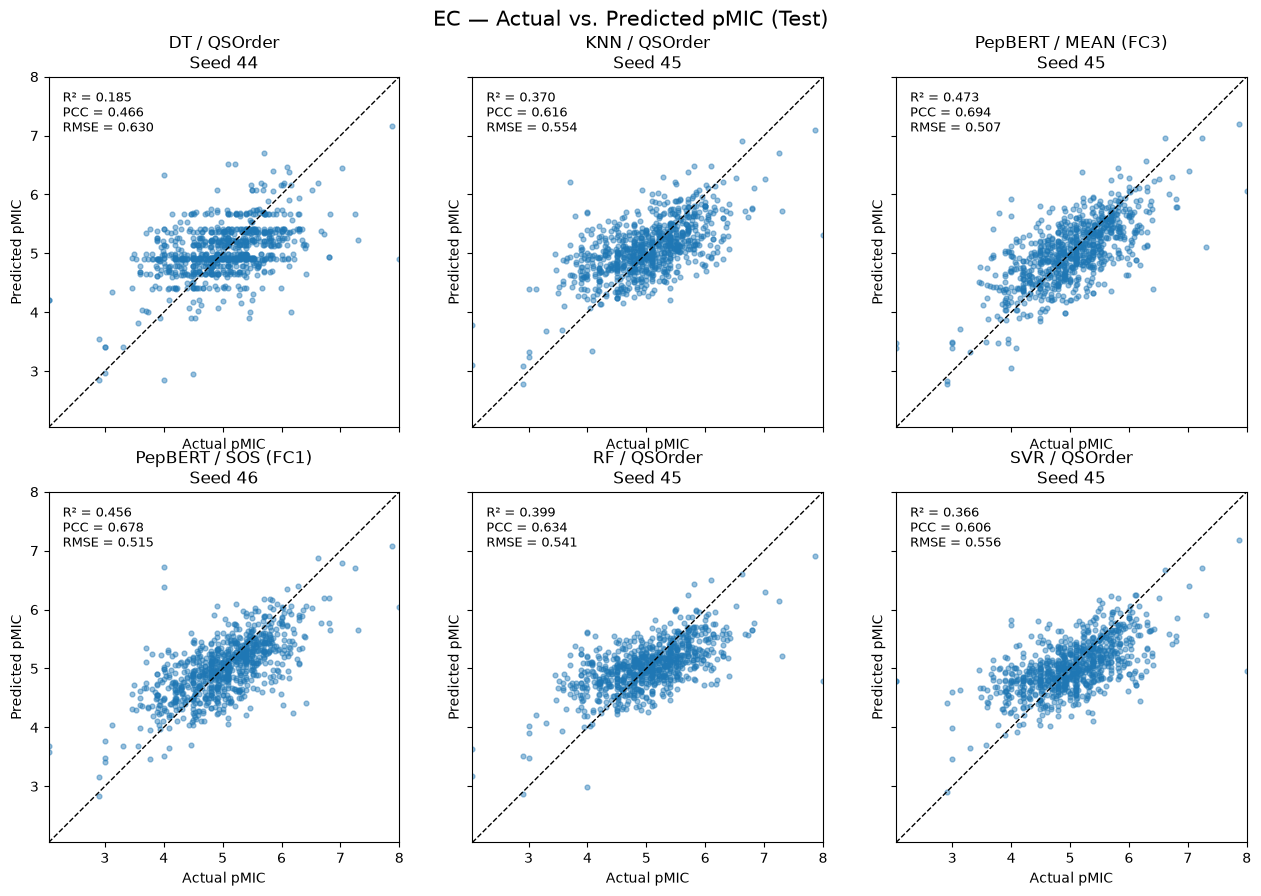

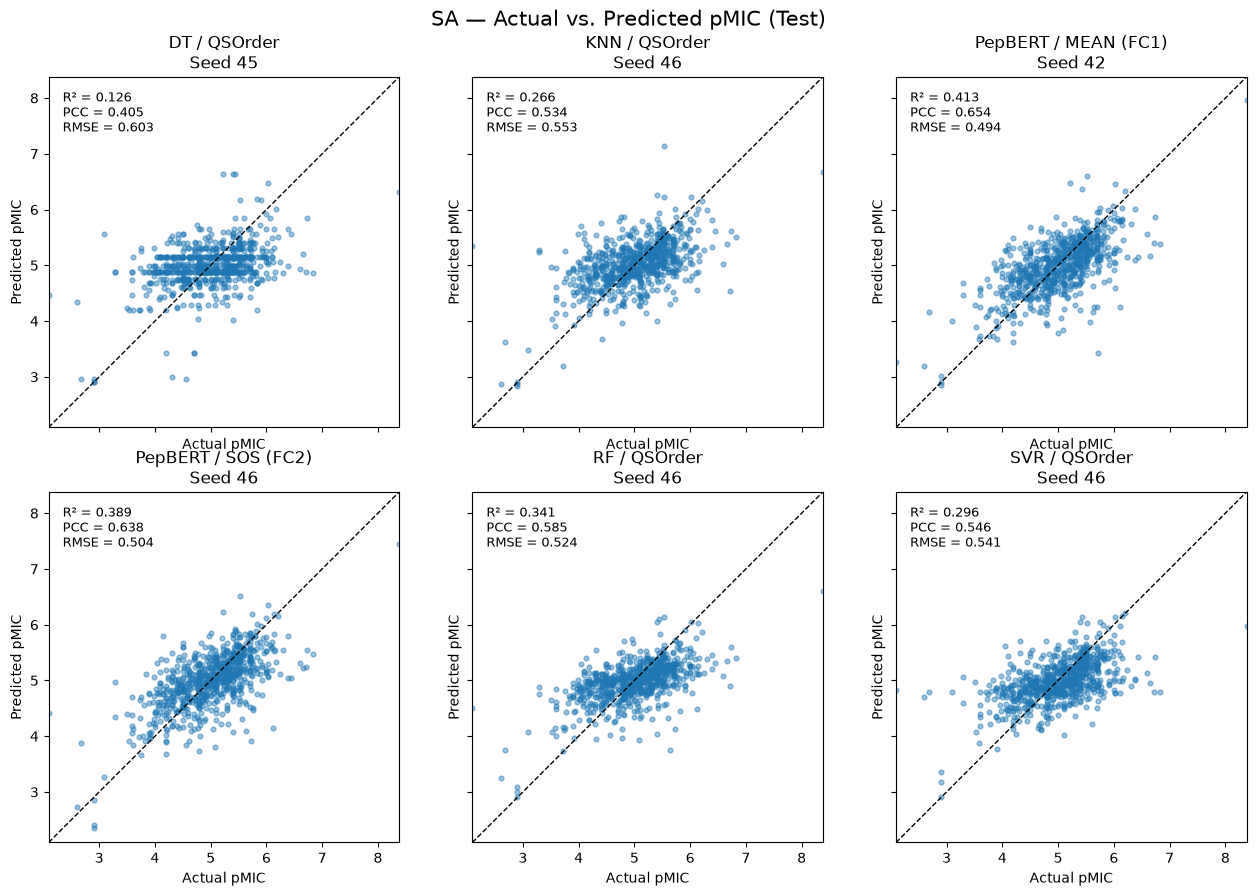

In [67]:

# Load representative models and saved test predictions
best_models_df = pd.read_csv(
    FIGURE_DATA_DIR / "best_models.csv"
)

predictions_df = pd.concat([
    pd.read_csv(FIGURE_DATA_DIR / "ml_test_predictions.csv"),
    pd.read_csv(FIGURE_DATA_DIR / "pepbert_test_predictions.csv")
], ignore_index=True)

# Plot representative models
for target in ["EC", "SA"]:
    selected = best_models_df[
        best_models_df["Dataset"] == target
    ]

    fig, axes = plt.subplots(
        2, 3, figsize=(13, 9),
        sharex=True, sharey=True
    )

    for ax, (_, row) in zip(axes.flat, selected.iterrows()):
        df = predictions_df[
            (predictions_df["Dataset"] == target)
            & (predictions_df["Model"] == row["Model"])
            & (predictions_df["Feature"] == row["Feature"])
            & (predictions_df["Seed"] == row["Seed"])
        ]

        actual = df["Actual"].to_numpy()
        predicted = df["Predicted"].to_numpy()

        metrics = evaluate_regression(actual, predicted)

        ax.scatter(actual, predicted, s=12, alpha=0.45)

        ax.set_title(
            f"{row['Model']} / {row['Feature']}\n"
            f"Seed {int(row['Seed'])}"
        )

        ax.text(
            0.04, 0.96,
            f"R² = {metrics['R2']:.3f}\n"
            f"PCC = {metrics['PCC']:.3f}\n"
            f"RMSE = {metrics['RMSE']:.3f}",
            transform=ax.transAxes,
            va="top",
            fontsize=9
        )

    # Common axis range
    df_target = predictions_df[
        predictions_df["Dataset"] == target
    ]

    limits = [
        min(df_target["Actual"].min(), df_target["Predicted"].min()),
        max(df_target["Actual"].max(), df_target["Predicted"].max())
    ]

    for ax in axes.flat:
        ax.plot(limits, limits, "k--", linewidth=1)
        ax.set_xlim(limits)
        ax.set_ylim(limits)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("Actual pMIC")
        ax.set_ylabel("Predicted pMIC")

    fig.suptitle(
        f"{target} — Actual vs. Predicted pMIC (Test)",
        fontsize=15
    )

    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / f"{target}_best_model_scatter.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


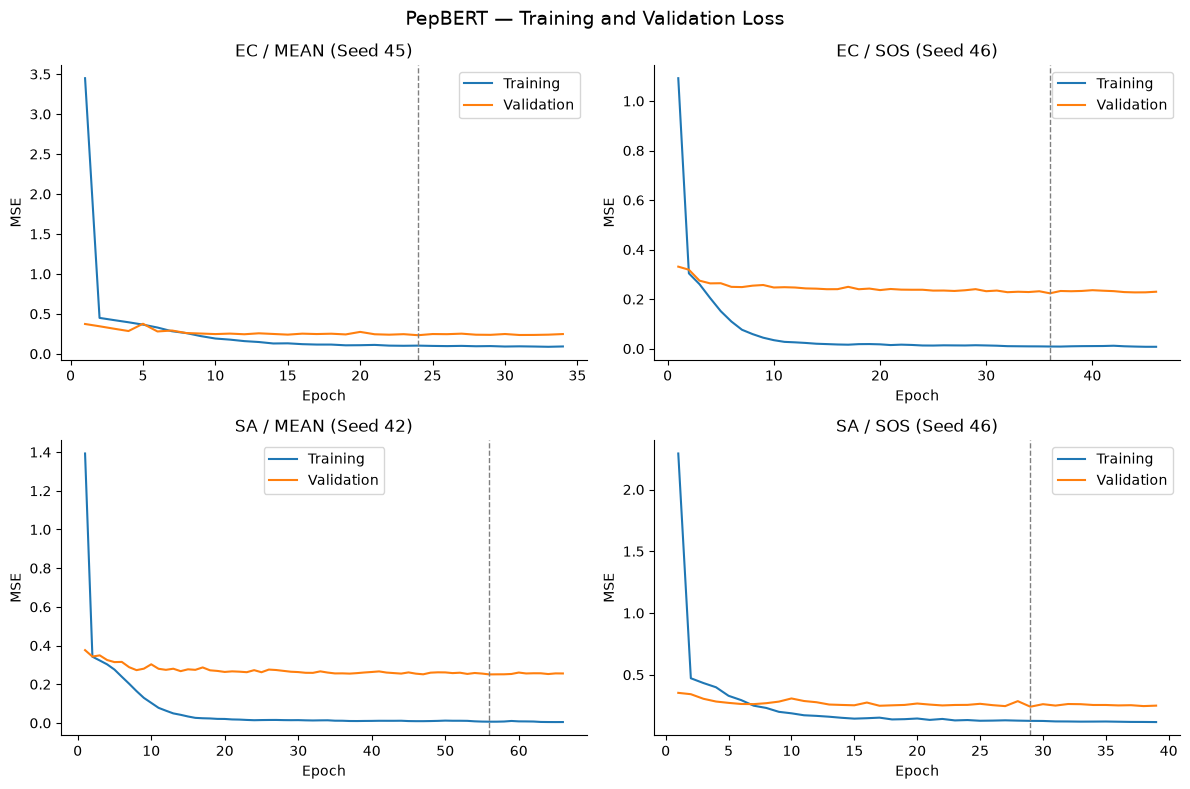

In [68]:

# Load representative models
best_models_df = pd.read_csv(
    FIGURE_DATA_DIR / "best_models.csv"
)

pepbert_best_df = best_models_df[
    best_models_df["Model"] == "PepBERT"
].copy()

# Find saved training histories
history_data = []

for _, row in pepbert_best_df.iterrows():
    target = row["Dataset"]
    pooling = row["Feature"].split()[0].lower()
    seed = int(row["Seed"])

    selected = pepbert_selected[
        (pepbert_selected["Dataset"] == target)
        & (pepbert_selected["Pooling"] == pooling)
        & (pepbert_selected["Seed"] == seed)
    ].iloc[0]

    stem = (
        f"FC{int(selected['FC_Layers'])}_"
        f"LR{selected['Learning_Rate']:.0e}_"
        f"WD{selected['Weight_Decay']:.0e}_"
        f"DO{selected['Dropout']:.1f}_"
        f"seed{seed}"
    )

    history_dir = (
        RESULT_DIR / "pepbert" / target / pooling / "grid_search"
    )

    matches = sorted(history_dir.glob(f"*{stem}*.csv"))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one history CSV for {target}/{pooling}: {stem}"
        )

    history = pd.read_csv(matches[0])

    # Identify history columns
    columns = {c.lower(): c for c in history.columns}

    def find_column(names):
        for name in names:
            if name in columns:
                return columns[name]
        raise KeyError(f"History columns: {list(history.columns)}")

    epoch_col = find_column(["epoch"])
    train_col = find_column(["train_mse", "train_loss"])
    val_col = find_column([
        "validation_mse", "val_mse",
        "validation_loss", "val_loss"
    ])

    history_data.append({
        "Dataset": target,
        "Pooling": pooling,
        "Seed": seed,
        "Epoch": history[epoch_col].to_numpy(),
        "Train": history[train_col].to_numpy(),
        "Validation": history[val_col].to_numpy()
    })

# Plot learning curves
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, data in zip(axes.flat, history_data):
    ax.plot(
        data["Epoch"], data["Train"],
        label="Training"
    )
    ax.plot(
        data["Epoch"], data["Validation"],
        label="Validation"
    )

    best_idx = np.argmin(data["Validation"])

    ax.axvline(
        data["Epoch"][best_idx],
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.set_title(
        f"{data['Dataset']} / {data['Pooling'].upper()} "
        f"(Seed {data['Seed']})"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "PepBERT — Training and Validation Loss",
    fontsize=14
)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "pepbert_best_model_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


In [69]:

# Load original ML validation records
original_ml = []

for _, row in ml_best.iterrows():
    target = row["Dataset"]
    model = row["Model"]
    feature = row["Feature"]

    path = (
        RESULT_DIR / "traditional_ml" / target
        / f"{model}_{feature}_grid_search.csv"
    )

    grid = pd.read_csv(path)
    best_params = json.loads(row["Best_Parameters"])

    selected = grid[
        grid["Parameters"].apply(
            lambda x: json.loads(x) == best_params
        )
    ].copy()

    selected["Dataset"] = target
    selected["Model"] = model
    selected["Feature"] = feature

    original_ml.append(
        selected[
            ["Dataset", "Model", "Feature", "Seed", "Validation_MSE"]
        ]
    )

original_ml = pd.concat(original_ml, ignore_index=True)

# Load original PepBERT validation records
original_pepbert = pepbert_selected[
    ["Dataset", "Pooling", "FC_Layers", "Seed", "Validation_MSE"]
].copy()

original_pepbert["Model"] = "PepBERT"
original_pepbert["Feature"] = (
    original_pepbert["Pooling"].str.upper()
    + " (FC"
    + original_pepbert["FC_Layers"].astype(str)
    + ")"
)

original_pepbert = original_pepbert[
    ["Dataset", "Model", "Feature", "Seed", "Validation_MSE"]
]

# Combine original results
original = pd.concat(
    [original_ml, original_pepbert],
    ignore_index=True
).rename(columns={"Validation_MSE": "Original_MSE"})

# Load recalculated validation results
recalculated = pd.read_csv(
    COMPARE_DIR / "validation_results.csv"
)[["Dataset", "Model", "Feature", "Seed", "MSE"]]

recalculated = recalculated.rename(
    columns={"MSE": "Recalculated_MSE"}
)

# Compare seed-level MSE
comparison = original.merge(
    recalculated,
    on=["Dataset", "Model", "Feature", "Seed"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

comparison["Absolute_Difference"] = (
    comparison["Original_MSE"]
    - comparison["Recalculated_MSE"]
).abs()

tolerance = 1e-4

comparison["Match"] = (
    comparison["_merge"].eq("both")
    & comparison["Absolute_Difference"].le(tolerance)
)

comparison = comparison.drop(columns="_merge")

# Save reproducibility results
comparison.to_csv(
    COMPARE_DIR / "validation_reproducibility.csv",
    index=False
)

print(f"Total comparisons: {len(comparison)}")
print(f"Matched: {comparison['Match'].sum()}")
print(f"Mismatched: {(~comparison['Match']).sum()}")

print("\nMaximum absolute difference:")
display(
    comparison.groupby("Model")["Absolute_Difference"]
    .max()
    .round(8)
)

if comparison["Match"].all():
    print("\nPASS: All validation MSE values are reproduced.")
else:
    print("\nWARNING: Validation MSE discrepancies detected.")
    display(
        comparison.loc[~comparison["Match"]].round(6)
    )


Total comparisons: 60
Matched: 60
Mismatched: 0

Maximum absolute difference:


Model
DT         0.000000e+00
KNN        0.000000e+00
PepBERT    3.000000e-08
RF         0.000000e+00
SVR        0.000000e+00
Name: Absolute_Difference, dtype: float64


PASS: All validation MSE values are reproduced.
